# Check VLM tags — `datasets/crops/vae_256_vlm-tags`

Sanity-check the VLM annotations produced for the 256px cell crops.

* **Ground truth** = the phase folder that contains each `*.json` tag (untagged folders ignored).
* **Prediction** = the `chromosome_and_nuclear_dynamics.detailed_mitotic_stage` field.

Outputs:

1. Confusion matrix (raw fine + coarsened to the folder vocabulary), shown as row percentages with phases in biological order (interphase -> prophase -> metaphase -> anaphase -> telophase).
2. Frequency of the distinct values of every description field (ignoring `reasoning`).
3. Progress tracked with `tqdm`.

### Imports

In [1]:
%matplotlib inline
import glob
import json
import os
import sys
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
)
from tqdm import tqdm

### Setup & load (single `tqdm` pass)

Set `ONLY_TEST = True` to restrict the **whole** analysis to the `test` split; `False` keeps every split. Untagged folders are always ignored.

In [2]:
sys.path.append("../../")
os.chdir("../..")

ROOT = "datasets/crops/vae_256_vlm-tags"
# Toggle: True = analyze ONLY the `test` split (train/val ignored); False = all splits.
ONLY_TEST = True
SECTIONS = [
    "geometry_and_fov",
    "chromosome_and_nuclear_dynamics",
    "optics_color_and_artifacts",
]
# `reasoning` is free-text and is excluded from the value-frequency analysis.

all_files = sorted(glob.glob(f"{ROOT}/**/*.json", recursive=True))
# Ignore the untagged folders (their 'class' is not a real phase).
labeled_files = [f for f in all_files if "/untagged/" not in f]
if ONLY_TEST:
    labeled_files = [f for f in labeled_files if f.startswith(f"{ROOT}/test/")]
scope = "test only" if ONLY_TEST else "train + val + test"
print(f"{len(all_files)} JSON tags total; analyzing {len(labeled_files)} labeled "
      f"(non-untagged, {scope}).")

rows = []  # (folder, detailed_mitotic_stage)
field_values = {sec: {} for sec in SECTIONS}  # section -> field -> Counter(value)

for path in tqdm(labeled_files, desc="Analyzing VLM tags", unit="tag"):
    with open(path) as fh:
        tag = json.load(fh)
    folder = os.path.basename(os.path.dirname(path))
    stage = tag["chromosome_and_nuclear_dynamics"]["detailed_mitotic_stage"]
    rows.append((folder, stage))
    for sec in SECTIONS:
        for key, val in tag[sec].items():
            counter = field_values[sec].setdefault(key, Counter())
            if isinstance(val, list):
                counter.update(str(v) for v in val)  # count each list element
            else:
                counter[str(val)] += 1

41239 JSON tags total; analyzing 4700 labeled (non-untagged, test only).


Analyzing VLM tags: 100%|██████████| 4700/4700 [00:00<00:00, 42212.30tag/s]


## 1. Confusion matrix

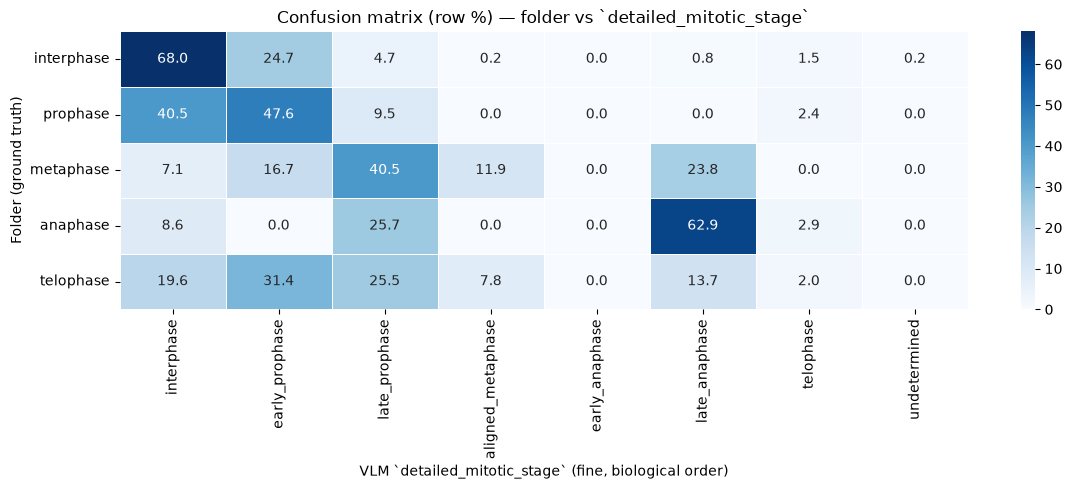

stage,interphase,early_prophase,late_prophase,aligned_metaphase,early_anaphase,late_anaphase,telophase,undetermined
folder,,,,,,,,
interphase,68.035320,24.657837,4.701987,0.220751,0.0,0.772627,1.456954,0.154525
prophase,40.476190,47.619048,9.523810,0.000000,0.0,0.000000,2.380952,0.000000
metaphase,7.142857,16.666667,40.476190,11.904762,0.0,23.809524,0.000000,0.000000
anaphase,8.571429,0.000000,25.714286,0.000000,0.0,62.857143,2.857143,0.000000
telophase,19.607843,31.372549,25.490196,7.843137,0.0,13.725490,1.960784,0.000000


In [3]:
df = pd.DataFrame(rows, columns=["folder", "stage"])

# Biological (cell-cycle) order for both axes.
TRUE_ORDER = ["interphase", "prophase", "metaphase", "anaphase", "telophase"]
# Fine columns grouped by phase, then early_x, x, late_x; `undetermined` last.
PRED_ORDER = [
    "interphase",
    "early_prophase",
    "late_prophase",
    "aligned_metaphase",
    "early_anaphase",
    "late_anaphase",
    "telophase",
    "undetermined",
]

raw_cm = (
    pd.crosstab(df["folder"], df["stage"])
    .reindex(index=TRUE_ORDER, columns=PRED_ORDER, fill_value=0)
)
raw_pct = raw_cm.div(raw_cm.sum(axis=1), axis=0) * 100

plt.figure(figsize=(12, 5))
ax = sns.heatmap(raw_pct, annot=True, fmt=".1f", cmap="Blues", cbar=True, linewidths=0.5)
# Keep the folder labels horizontal; the long phase names collide when rotated.
ax.tick_params(axis="y", labelrotation=0)
for lbl in ax.get_yticklabels():
    lbl.set_ha("right")
plt.xlabel("VLM `detailed_mitotic_stage` (fine, biological order)")
plt.ylabel("Folder (ground truth)")
plt.title("Confusion matrix (row %) — folder vs `detailed_mitotic_stage`")
plt.tight_layout()
plt.show()

raw_pct

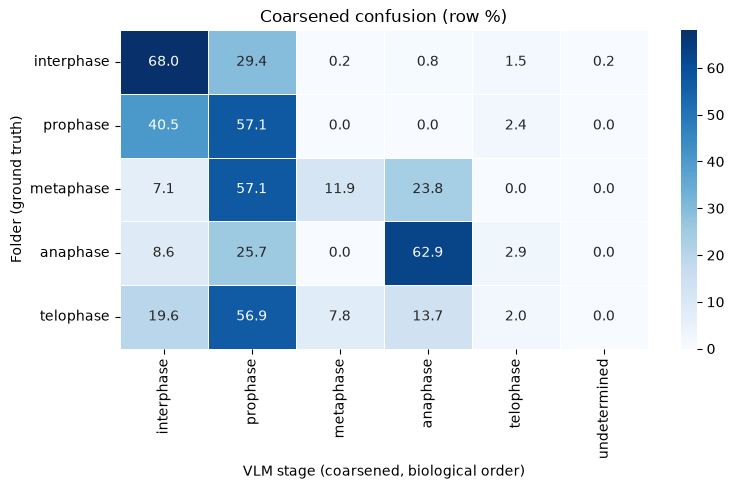

Overall coarse accuracy (coarsened VLM stage == folder): 0.667 (3134/4700)


coarse,interphase,prophase,metaphase,anaphase,telophase,undetermined
folder,,,,,,
interphase,68.035320,29.359823,0.220751,0.772627,1.456954,0.154525
prophase,40.476190,57.142857,0.000000,0.000000,2.380952,0.000000
metaphase,7.142857,57.142857,11.904762,23.809524,0.000000,0.000000
anaphase,8.571429,25.714286,0.000000,62.857143,2.857143,0.000000
telophase,19.607843,56.862745,7.843137,13.725490,1.960784,0.000000


In [4]:
# The VLM emits a finer vocabulary than the 5 folder classes -> collapse it back for
# a like-for-like matrix. `undetermined` is kept as its own (always-wrong) column.
COARSE_MAP = {
    "early_prophase": "prophase",
    "late_prophase": "prophase",
    "aligned_metaphase": "metaphase",
    "early_anaphase": "anaphase",
    "late_anaphase": "anaphase",
    "telophase": "telophase",
    "interphase": "interphase",
    "undetermined": "undetermined",
}
COARSE_ORDER = [
    "interphase",
    "prophase",
    "metaphase",
    "anaphase",
    "telophase",
    "undetermined",
]

df["coarse"] = df["stage"].map(COARSE_MAP)
coarse_cm = (
    pd.crosstab(df["folder"], df["coarse"])
    .reindex(index=TRUE_ORDER, columns=COARSE_ORDER, fill_value=0)
)
coarse_pct = coarse_cm.div(coarse_cm.sum(axis=1), axis=0) * 100

plt.figure(figsize=(8, 5))
ax = sns.heatmap(coarse_pct, annot=True, fmt=".1f", cmap="Blues", linewidths=0.5)
# Keep the folder labels horizontal; the long phase names collide when rotated.
ax.tick_params(axis="y", labelrotation=0)
for lbl in ax.get_yticklabels():
    lbl.set_ha("right")
plt.xlabel("VLM stage (coarsened, biological order)")
plt.ylabel("Folder (ground truth)")
plt.title("Coarsened confusion (row %)")
plt.tight_layout()
plt.show()

accuracy = (df["coarse"] == df["folder"]).mean()
print(f"Overall coarse accuracy (coarsened VLM stage == folder): {accuracy:.3f} "
      f"({int(round(accuracy * len(df)))}/{len(df)})")
coarse_pct

### Metrics (coarsened)

Whole-set accuracy + macro/weighted F1 and per-class precision/recall/F1 over the full labeled set. Predictions of `undetermined` match no class, so they count as errors for their true class (they drag recall down). Per-class recall is that class's accuracy; micro-F1 equals accuracy, so it is not shown separately.

In [5]:
labels = TRUE_ORDER  # the 5 folder classes; 'undetermined' is not a label
y_true = df["folder"]
y_pred = df["coarse"]

precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=labels, zero_division=0
)
metrics_df = pd.DataFrame(
    {
        "precision": precision,
        "recall (= per-class accuracy)": recall,
        "f1": f1,
        "support": support,
    },
    index=labels,
)

overall_acc = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro", labels=labels, zero_division=0)
weighted_f1 = f1_score(y_true, y_pred, average="weighted", labels=labels)
n_undetermined = int((y_pred == "undetermined").sum())

print(f"Whole set (n={len(df)}): accuracy={overall_acc:.4f}  "
      f"macro-F1={macro_f1:.4f}  weighted-F1={weighted_f1:.4f}")
print(f"'undetermined' predictions (counted as errors): {n_undetermined} "
      f"({n_undetermined / len(df) * 100:.2f}%)")

metrics_df.round(3)

Whole set (n=4700): accuracy=0.6668  macro-F1=0.2847  weighted-F1=0.7821
'undetermined' predictions (counted as errors): 7 (0.15%)


,precision,recall (= per-class accuracy),f1,support
interphase,0.989,0.680,0.806,4530
prophase,0.017,0.571,0.033,42
metaphase,0.263,0.119,0.164,42
anaphase,0.297,0.629,0.404,35
telophase,0.014,0.020,0.017,51


## 2. Frequency of distinct field values

For every description field (except `reasoning`), how often each distinct value appears across all labeled samples. `noise_and_digital_artifacts` is a list, so it is counted per element; booleans appear as `True`/`False`.

In [6]:
for sec in SECTIONS:
    print("\n" + "=" * 78)
    print(sec)
    print("=" * 78)
    for field, counter in field_values[sec].items():
        total = sum(counter.values())
        is_list = field == "noise_and_digital_artifacts"
        suffix = "  [list: counted per element]" if is_list else ""
        print(f"\n--- {field}  ({len(counter)} distinct values, {total} occurrences){suffix}")
        for val, cnt in counter.most_common():
            print(f"    {cnt:6d}  {cnt / total * 100:5.1f}%  {val}")


geometry_and_fov

--- fov_type  (2 distinct values, 4700 occurrences)
      4378   93.1%  single_cell_cropped_from_dense_tissue
       322    6.9%  single_cell_with_partial_neighbors

--- zoom_and_crop_level  (3 distinct values, 4700 occurrences)
      4639   98.7%  tight_crop_nucleus_only
        37    0.8%  wide_field_multiple_cells
        24    0.5%  whole_single_cell_visible

--- cell_shape  (5 distinct values, 4700 occurrences)
      3242   69.0%  elongated_rectangular
      1235   26.3%  circular_rounded_protoplast
       213    4.5%  polyhedral
         6    0.1%  undefined_due_to_rupture
         4    0.1%  isodiametric_square

--- cell_wall_contrast  (3 distinct values, 4700 occurrences)
      2436   51.8%  faint_dark_borders
      2018   42.9%  high_contrast_bright_lines
       246    5.2%  not_visible

--- neighboring_cell_intrusion  (3 distinct values, 4700 occurrences)
      4350   92.6%  faint_neighboring_walls
       206    4.4%  clean_empty_borders
       144    3.1% 